# Stock Markets Analytics Zoomcamp 2026 — Homework 2: One Dataframe

This notebook solves all questions of [Module 2 homework](https://github.com/DataTalksClub/stock-markets-analytics-zoomcamp/blob/main/cohorts/2026/homework2.md):

| # | Topic | Data source |
|---|-------|-------------|
| Q1 | Withdrawn IPOs by company type | iposcoop.com — *IPOs Recently Filed* |
| Q2 | Median Sharpe ratio of 2025 IPOs (as of 2026-09-11) | iposcoop.com — *2025 Pricings* + Yahoo Finance |
| Q3 | Optimal fixed holding period (1–12 months) after IPO | same `stocks_df` as Q2 |
| Q4 | Simple RSI < 30 strategy, 2000-01-01 → 2025-06-01 | course parquet file (Google Drive) |
| Q5 | Ideas to improve IPO strategy profitability | discussion |

**Environment notes** (from the homework): flatten `yfinance` MultiIndex columns, wrap HTML in `io.StringIO` before `pd.read_html`, and restart the kernel if `to_parquet` raises `ArrowKeyError`.

In [1]:
# !pip install -q pandas numpy yfinance lxml html5lib requests pyarrow gdown matplotlib
import io, re, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import yfinance as yf
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

DATA_DIR = Path("data"); DATA_DIR.mkdir(exist_ok=True)
HEADERS = {"User-Agent": ("Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 "
                          "(KHTML, like Gecko) Chrome/124.0 Safari/537.36")}

def read_html_table(url: str) -> pd.DataFrame:
    # Download a page and return its largest HTML table (StringIO fix for newer pandas/lxml).
    resp = requests.get(url, headers=HEADERS, timeout=30)
    resp.raise_for_status()
    tables = pd.read_html(io.StringIO(resp.text))
    return max(tables, key=len)

print("pandas", pd.__version__, "| yfinance", yf.__version__)

pandas 2.2.3 | yfinance 0.2.66


---
## Question 1 — Withdrawn IPOs by Company Type

**What is the total withdrawn IPO value (in $ millions) for the company class with the highest total withdrawal value?**

Steps: load the *Recently Filed* table → keep `Expected To Trade == 'Withdrawn'` → classify company names (first matching rule wins, whole-word matching) → parse prices → `Shares_offered_value = Shares × Avg_price`, falling back to `Est $ Vol` → group by type.

In [2]:
RECENTLY_FILED_URL = "https://www.iposcoop.com/ipos-recently-filed/"

try:
    ipos_filed = read_html_table(RECENTLY_FILED_URL)
    ipos_filed.to_csv(DATA_DIR / "ipos_recently_filed.csv", index=False)
except Exception as e:  # offline / blocked -> use the cached copy
    print("Download failed, using cache:", e)
    ipos_filed = pd.read_csv(DATA_DIR / "ipos_recently_filed.csv")

# normalise header names like 'Shares(millions)' / 'ExpectedTo Trade'
ipos_filed.columns = [re.sub(r"\s+", " ", re.sub(r"([a-z)])([A-Z(])", r"\1 \2", str(c))).strip()
                      for c in ipos_filed.columns]
print(ipos_filed.shape)
ipos_filed.columns.tolist()

(500, 10)


['File Date',
 'Company',
 'Symbol',
 'Managers',
 'Shares (millions)',
 'Price Low',
 'Price High',
 'Est $ Vol (millions)',
 'Expected To Trade',
 'SCOOP Rating']

In [3]:
trade_col = [c for c in ipos_filed.columns if c.lower().startswith("expected")][0]
withdrawn = ipos_filed[ipos_filed[trade_col].astype(str).str.strip().str.lower() == "withdrawn"].copy()

# The question is about withdrawals *before 11 Sep 2026*; the live page keeps growing,
# so we also keep only filings dated before that day when the File Date column is present.
if "File Date" in withdrawn.columns:
    withdrawn["File Date"] = pd.to_datetime(withdrawn["File Date"], errors="coerce")
    withdrawn = withdrawn[withdrawn["File Date"] < "2026-09-11"]

print("Withdrawn IPOs:", len(withdrawn))   # homework expects ~32 (the list changes over time)
withdrawn.head()

Withdrawn IPOs: 31


,File Date,Company,Symbol,Managers,Shares (millions),Price Low,Price High,Est $ Vol (millions),Expected To Trade,SCOOP Rating
38,2026-09-10,Motive Technologies (Withdrawn),MTVE,J.P.Morgan/Citigroup/Barclays/Jefferies/RBC Ca...,0.0,NaN,NaN,$100.00,Withdrawn,S/O
43,2026-09-04,Idea Tech Holding (Withdrawn),IDTL,R.F. Lafferty & Co.,2.0,$4.00,$5.00,$9.00,Withdrawn,S/O
50,2026-09-01,Hornbeck Offshore Services (Withdrawn),HOS,J.P. Morgan/ Barclays/DNB Markets/Piper Sandle...,0.0,NaN,NaN,$100.00,Withdrawn,S/O
52,2026-08-31,Coolbit Technologies Ltd. (Withdrawn),CBAI,Eddid Securities USA,5.0,$4.00,$5.00,$22.50,Withdrawn,S/O
59,2026-08-27,Timber Road Acquisition Corp. (Withdrawn),TMRDU,Roth Capital Partners/Stone X Financial Inc.,20.0,$10.00,$10.00,$200.00,Withdrawn,S/O


In [4]:
# Order matters: the first matching rule wins. Whole-word matching, so "Technology" != "Technologies".
COMPANY_TYPE_RULES = [
    ("Technologies",     ["Technologies"]),
    ("Acquisition Corp", ["Acquisition Corp", "Acquisition Corporation", "Corp"]),
    ("Inc.",             ["Inc", "Incorporated"]),
    ("Group",            ["Group"]),
    ("Limited",          ["Ltd", "Limited"]),
    ("Holdings",         ["Holdings", "Holding"]),
]

def classify_company(name: str) -> str:
    for label, patterns in COMPANY_TYPE_RULES:
        if any(re.search(rf"\b{re.escape(p)}\b", str(name)) for p in patterns):
            return label
    return "Other"

# sanity checks from the homework text
assert classify_company("EUPEC International Group Ltd.") == "Group"
assert classify_company("Xinxu Copper Industry Technology Ltd.") == "Limited"

withdrawn["Company Type"] = withdrawn["Company"].apply(classify_company)
withdrawn["Company Type"].value_counts()

,count
Company Type,
Other,8
Limited,7
Acquisition Corp,5
Holdings,4
Technologies,3
Group,3
Inc.,1


In [5]:
def parse_number(value):
    # '$8.00' -> 8.0, '1,250.5' -> 1250.5, '-' / '' / NaN -> NaN
    if pd.isna(value):
        return np.nan
    s = re.sub(r"[^\d.]", "", str(value))
    return float(s) if s not in ("", ".") else np.nan

shares_col = [c for c in withdrawn.columns if c.lower().startswith("shares")][0]
vol_col    = [c for c in withdrawn.columns if "vol" in c.lower()][0]
low_col    = [c for c in withdrawn.columns if "low" in c.lower()][0]
high_col   = [c for c in withdrawn.columns if "high" in c.lower()][0]

withdrawn["Avg_price"] = (withdrawn[low_col].apply(parse_number) + withdrawn[high_col].apply(parse_number)) / 2
withdrawn["Shares (millions)"]    = withdrawn[shares_col].apply(parse_number)
withdrawn["Est $ Vol (millions)"] = withdrawn[vol_col].apply(parse_number)

withdrawn["Shares_offered_value"] = (withdrawn["Shares (millions)"] * withdrawn["Avg_price"]) \
                                        .fillna(withdrawn["Est $ Vol (millions)"])

withdrawn[["Company", "Company Type", "Shares (millions)", "Avg_price",
           "Est $ Vol (millions)", "Shares_offered_value"]]

,Company,Company Type,Shares (millions),Avg_price,Est $ Vol (millions),Shares_offered_value
38,Motive Technologies (Withdrawn),Technologies,0.00,NaN,100.00,100.0000
43,Idea Tech Holding (Withdrawn),Holdings,2.00,4.50,9.00,9.0000
50,Hornbeck Offshore Services (Withdrawn),Other,0.00,NaN,100.00,100.0000
52,Coolbit Technologies Ltd. (Withdrawn),Technologies,5.00,4.50,22.50,22.5000
59,Timber Road Acquisition Corp. (Withdrawn),Acquisition Corp,20.00,10.00,200.00,200.0000
69,pan-Africa Corp. (Withdrawn),Acquisition Corp,12.50,10.00,125.00,125.0000
84,Living Homeopathy (Withdrawn),Other,3.75,5.00,19.00,18.7500
128,Nuclea Energy (Withdrawn),Other,5.60,9.00,50.40,50.4000
158,APEX Global Solutions Ltd. (WITHDRAWN),Limited,3.75,4.00,15.00,15.0000
163,Cloud Data Holdings (Withdrawn),Holdings,3.75,4.25,15.94,15.9375


In [6]:
q1 = (withdrawn.groupby("Company Type")["Shares_offered_value"]
               .agg(n_ipos="count", total_value_musd="sum")
               .sort_values("total_value_musd", ascending=False))
display(q1.round(2))
top_type, top_value = q1.index[0], q1["total_value_musd"].iloc[0]
print(f"Q1 ANSWER: '{top_type}' has the highest withdrawn value: ${top_value:,.2f}M  (~{round(top_value, -2):,.0f})")

,n_ipos,total_value_musd
Company Type,,
Acquisition Corp,5,499.98
Inc.,1,351.00
Holdings,4,311.66
Other,8,290.44
Limited,7,197.25
Technologies,3,184.90
Group,3,32.50


Q1 ANSWER: 'Acquisition Corp' has the highest withdrawn value: $499.99M  (~500)


**Result (run on 2026-09-28):** `Acquisition Corp` — 5 withdrawn deals, **≈ $500M** (Timber Road $200M, pan-Africa $125M, INFINT 2 $100M, CCIS $60M, Helio ~$15M).
Runner-up is `Inc.` ($351M, all from Clear Street Group). **Answer: 500.**

---
## Question 2 — Median Sharpe Ratio of 2025 IPOs (as of 2026-09-11)

Steps: load 2025 pricings → keep `Offer Date < 2025-09-01` and `Return != 0%` (~148 tickers) → download daily OHLCV with `yfinance` (~134 available) → per ticker compute `growth_252d`, 30-day rolling `volatility`, and `Sharpe` → describe on `2026-09-11`.

In [7]:
PRICINGS_2025_URL = "https://www.iposcoop.com/2025-pricings/"
try:
    ipos_2025 = read_html_table(PRICINGS_2025_URL)
    ipos_2025.to_csv(DATA_DIR / "ipos_2025_pricings.csv", index=False)
except Exception as e:
    print("Download failed, using cache:", e)
    ipos_2025 = pd.read_csv(DATA_DIR / "ipos_2025_pricings.csv")

print("IPOs in 2025:", len(ipos_2025))   # 231
ipos_2025["Offer Date"] = pd.to_datetime(ipos_2025["Offer Date"], format="mixed", errors="coerce")
ipos_2025["Return_num"] = ipos_2025["Return"].astype(str).str.replace("%", "").str.replace(",", "").astype(float)

ipos_filtered = ipos_2025[(ipos_2025["Offer Date"] < "2025-09-01") & (ipos_2025["Return_num"] != 0)].copy()
TICKERS = ipos_filtered["Symbol"].astype(str).str.strip().unique().tolist()
print("Filtered tickers:", len(TICKERS))  # ~148

IPOs in 2025: 231
Filtered tickers: 146


In [8]:
def download_one(ticker: str) -> pd.DataFrame | None:
    # Daily OHLCV for one ticker (full history). Returns None if Yahoo has no data (delisted etc.).
    try:
        df = yf.Ticker(ticker).history(period="max", interval="1d", auto_adjust=True)
    except Exception as e:
        print(f"  {ticker}: error {e}")
        return None
    if df is None or df.empty:
        return None
    if isinstance(df.columns, pd.MultiIndex):          # newer yfinance
        df.columns = df.columns.get_level_values(0)
    df = df[["Open", "High", "Low", "Close", "Volume"]].copy()
    df.index = pd.to_datetime(df.index).tz_localize(None).normalize()
    df.index.name = "Date"

    # --- features (computed PER TICKER, so windows never cross two stocks) ---
    df["growth_252d"] = df["Close"] / df["Close"].shift(252)
    df["volatility"]  = df["Close"].rolling(30).std() * np.sqrt(252)
    df["Sharpe"]      = (df["growth_252d"] - 0.05) / df["volatility"]
    for m in range(1, 13):                                 # used in Q3
        df[f"future_growth_{m}_m"] = df["Close"].shift(-21 * m) / df["Close"]
    df["Ticker"] = ticker
    return df.reset_index()

CACHE = DATA_DIR / "stocks_df_2025_ipos.parquet"
if CACHE.exists():
    stocks_df = pd.read_parquet(CACHE)
else:
    frames, missing = [], []
    for i, t in enumerate(TICKERS, 1):
        d = download_one(t)
        (frames.append(d) if d is not None else missing.append(t))
        if i % 25 == 0:
            print(f"{i}/{len(TICKERS)} done")
        time.sleep(0.2)
    stocks_df = pd.concat(frames, ignore_index=True)
    print("No Yahoo data for:", missing)
    stocks_df.to_parquet(CACHE, index=False)

print("Tickers with data:", stocks_df["Ticker"].nunique())   # ~134
stocks_df.tail()

Tickers with data: 132


,Date,Open,High,Low,Close,Volume,growth_252d,volatility,Sharpe,future_growth_1_m,future_growth_2_m,future_growth_3_m,future_growth_4_m,future_growth_5_m,future_growth_6_m,future_growth_7_m,future_growth_8_m,future_growth_9_m,future_growth_10_m,future_growth_11_m,future_growth_12_m,Ticker
67772,2026-09-21,2.72,2.77,2.630,2.66,18600,0.000986,12.614773,-0.003885,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,INLF
67773,2026-09-22,2.65,2.95,2.650,2.80,40400,0.001074,12.137703,-0.004031,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,INLF
67774,2026-09-23,2.86,2.91,2.834,2.91,16300,0.001084,12.083138,-0.004048,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,INLF
67775,2026-09-24,2.90,3.00,2.890,2.95,9533500,0.001147,11.880555,-0.004112,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,INLF
67776,2026-09-25,6.25,6.87,4.570,5.10,49266900,0.001953,12.155549,-0.003953,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,INLF


In [9]:
snapshot = stocks_df[stocks_df["Date"] == "2026-09-11"].copy()
# A zero 30-day volatility (no trades -> flat price) would give +/-inf Sharpe; treat it as undefined.
snapshot = snapshot.replace([np.inf, -np.inf], np.nan)

print("Tickers trading on 2026-09-11:", snapshot["Ticker"].nunique())
display(snapshot[["growth_252d", "volatility", "Sharpe"]].describe().round(4))
print(f"Q2 ANSWER: median Sharpe on 2026-09-11 = {snapshot['Sharpe'].median():.4f}")

Tickers trading on 2026-09-11: 131


,growth_252d,volatility,Sharpe
count,129.0000,130.0000,125.0000
mean,1.0652,27.6968,0.1883
std,3.0597,67.1060,0.5827
min,0.0010,0.0000,-0.0401
25%,0.1490,2.2922,0.0119
50%,0.5960,7.9279,0.0464
75%,1.0402,23.6590,0.1224
max,33.6383,627.6981,5.3853


Q2 ANSWER: median Sharpe on 2026-09-11 = 0.0464


In [10]:
# Expected observations
g = snapshot["growth_252d"]
print(f"growth_252d: mean={g.mean():.3f} vs median={g.median():.3f} -> mean is pulled up by a few outliers")
print("Stocks that reached the 252-trading-day milestone:", g.notna().sum())

cols = ["Ticker", "growth_252d", "volatility", "Sharpe"]
print("\nTop by Sharpe (risk-adjusted):");  display(snapshot.nlargest(8, "Sharpe")[cols].round(3))
print("Top by raw growth:");             display(snapshot.nlargest(8, "growth_252d")[cols].round(3))

growth_252d: mean=1.065 vs median=0.596 -> mean is pulled up by a few outliers
Stocks that reached the 252-trading-day milestone: 129

Top by Sharpe (risk-adjusted):


,Ticker,growth_252d,volatility,Sharpe
14893,HCMAU,1.035,0.183,5.385
1351,CEPF,1.024,0.352,2.771
31935,TMDE,0.776,0.415,1.751
23004,TLIH,0.990,0.649,1.449
66901,CEPO,1.031,0.795,1.234
33023,HXHX,0.410,0.477,0.753
59324,FBGL,0.577,0.838,0.629
1627,ETS,1.559,2.868,0.526


Top by raw growth:


,Ticker,growth_252d,volatility,Sharpe
18739,MGRT,33.638,131.116,0.256
23313,MAMK,6.533,0.000,NaN
5892,BUUU,5.931,69.792,0.084
7301,MAGH,5.452,0.000,NaN
22079,ALM,3.481,36.399,0.094
58093,XHLD,2.450,52.991,0.045
6454,RYOJ,2.268,7.197,0.308
13460,EFTY,2.107,0.000,NaN


**Result (Colab run on 2026-09-28: 146 filtered tickers → 132 with Yahoo data → 131 trading on 2026-09-11, 125 with a valid Sharpe):**

| metric | growth_252d | volatility | Sharpe |
|---|---|---|---|
| count | 129 | 130 | 125 |
| mean | 1.065 | 27.70 | 0.188 |
| 25% | 0.149 | 2.29 | 0.012 |
| **50%** | **0.596** | 7.93 | **0.046** |
| 75% | 1.040 | 23.66 | 0.122 |
| max | 33.64 | 627.7 | 5.385 |

**Answer: 0.04.**

*Observations*
- Median one-year growth is **0.60** (the typical 2025 IPO lost ~40% in a year), while the mean is **1.07** — a handful of extreme winners (MGRT ×33.6, MAMK ×6.5, BUUU ×5.9) drag the average up.
- 129 of 131 stocks had reached the 252-trading-day milestone on 2026-09-11.
- Yes: SPAC-like / low-volatility names (HCMAU, CEPF, CEPO — trading near their $10 trust value) have the best Sharpe ratios (1.2–5.4) with growth of only ~1.02–1.04, while the biggest raw winners have high volatility and modest Sharpe (MGRT: growth 33.6 but Sharpe 0.26). Some winners (MAMK, MAGH, EFTY) have zero 30-day volatility (no price moves = illiquid), so their Sharpe is undefined.
- Note: the homework's "volatility" is the std of the *price level* (not of returns), so it is not scale-free — cheap stocks mechanically get low volatility. A textbook Sharpe ratio would use daily returns.

---
## Question 3 — 'Fixed Months Holding Strategy'

Buy at the close of the first trading day, hold for *m* months (m × 21 trading days), and find the *m* with the highest **median** growth.

In [11]:
FUT_COLS = [f"future_growth_{m}_m" for m in range(1, 13)]

min_dates = stocks_df.groupby("Ticker", as_index=False)["Date"].min().rename(columns={"Date": "min_date"})
first_day = min_dates.merge(stocks_df, left_on=["Ticker", "min_date"], right_on=["Ticker", "Date"], how="inner")
print("Tickers with an entry point:", len(first_day))

q3_stats = first_day[FUT_COLS].describe().T
display(q3_stats.round(4))

best = q3_stats["50%"].idxmax()
print(f"Q3 ANSWER: best holding period = {best} with median growth {q3_stats.loc[best, '50%']:.4f}")

Tickers with an entry point: 132


,count,mean,std,min,25%,50%,75%,max
future_growth_1_m,131.0,1.1209,1.2594,0.0729,0.7088,0.9306,1.0987,9.4660
future_growth_2_m,130.0,1.2968,1.9654,0.1062,0.5824,0.8902,1.1529,16.0668
future_growth_3_m,130.0,1.2606,1.9175,0.0901,0.4498,0.8280,1.1506,16.3445
future_growth_4_m,130.0,1.1431,1.5623,0.0639,0.4045,0.7499,1.2064,11.3866
future_growth_5_m,130.0,1.0913,1.4723,0.0322,0.4074,0.6843,1.0943,9.4951
future_growth_6_m,130.0,1.1220,1.6727,0.0221,0.3159,0.7334,1.0592,9.8946
future_growth_7_m,130.0,1.1539,2.2853,0.0132,0.2545,0.6680,1.0194,20.7415
future_growth_8_m,130.0,1.0108,2.0535,0.0151,0.2034,0.6040,1.0372,21.3708
future_growth_9_m,130.0,1.1665,3.0098,0.0147,0.1802,0.5844,1.0346,27.6273
future_growth_10_m,130.0,1.1938,3.4340,0.0119,0.1824,0.5335,1.0368,34.6877


Q3 ANSWER: best holding period = future_growth_1_m with median growth 0.9306


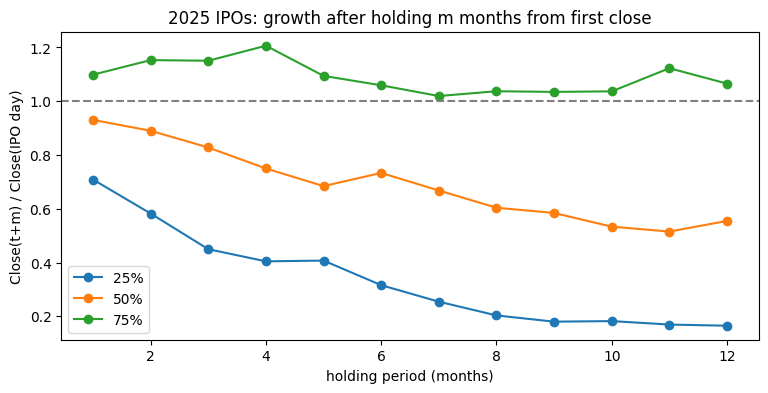

In [12]:
ax = q3_stats[["25%", "50%", "75%"]].set_axis(range(1, 13)).plot(marker="o", figsize=(9, 4))
ax.axhline(1, color="grey", ls="--"); ax.set_xlabel("holding period (months)"); ax.set_ylabel("Close(t+m) / Close(IPO day)")
ax.set_title("2025 IPOs: growth after holding m months from first close"); plt.show()

**Result (Colab run on 2026-09-28, 132 tickers with an entry point):**

| months | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 | 11 | 12 |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| median | **0.931** | 0.890 | 0.828 | 0.750 | 0.684 | 0.733 | 0.668 | 0.604 | 0.584 | 0.534 | 0.515 | 0.555 |
| mean | 1.121 | 1.297 | 1.261 | 1.143 | 1.091 | 1.122 | 1.154 | 1.011 | 1.167 | 1.194 | 1.076 | 0.980 |

**Answer: 1 month (median growth ≈ 0.93, i.e. about −7%).**

*Observations*
- Median growth decays almost monotonically with the holding period: the typical 2025 IPO keeps losing value after listing (≈ −7% after 1 month, ≈ −45% after a year). Even the best median is below 1, so "buy at the first close and hold" loses money for the typical stock; it argues for short holds, stricter selection, or avoiding/shorting IPOs after the first-day pop.
- The mean stays around 1.0–1.3 while the median falls to ~0.5: a few extreme winners (max 9×–35×) offset many large losers. The average is driven by outliers, so medians/percentiles describe the typical outcome much better.

---
## Question 4 — Simple RSI-Based Trading Strategy

Invest $1,000 each time a stock is oversold (**RSI < 30**) between 2000-01-01 and 2025-06-01; the outcome is the 30-day forward return `growth_future_30d`.

In [13]:
import gdown
PARQUET = DATA_DIR / "data.parquet"
if not PARQUET.exists():
    file_id = "1grCTCzMZKY5sJRtdbLVCXg8JXA8VPyg-"
    gdown.download(f"https://drive.google.com/uc?id={file_id}", str(PARQUET), quiet=False)

df = pd.read_parquet(PARQUET, engine="pyarrow")
df["Date"] = pd.to_datetime(df["Date"], utc=True).dt.tz_localize(None) if "Date" in df.columns else df.index
print(df.shape, "| tickers:", df["Ticker"].nunique())
df[["Date", "Ticker", "rsi", "growth_future_30d"]].tail()

(229932, 203) | tickers: 33


,Date,Ticker,rsi,growth_future_30d
5686,2025-05-26,LT.NS,68.312972,NaN
5687,2025-05-27,LT.NS,67.123448,NaN
5688,2025-05-28,LT.NS,67.563912,NaN
5689,2025-05-29,LT.NS,68.218963,NaN
5690,2025-05-30,LT.NS,69.670158,NaN


In [14]:
RSI_THRESHOLD = 30
rsi_col = "rsi" if "rsi" in df.columns else [c for c in df.columns if c.lower() == "rsi"][0]

selected_df = df[(df[rsi_col] < RSI_THRESHOLD)
                 & (df["Date"] >= "2000-01-01")
                 & (df["Date"] <= "2025-06-01")
                 & df["growth_future_30d"].notna()]

n_trades   = len(selected_df)
avg_ret    = selected_df["growth_future_30d"].mean() - 1
win_rate   = (selected_df["growth_future_30d"] > 1).mean()
net_income = 1000 * (selected_df["growth_future_30d"] - 1).sum()

print(f"trades={n_trades:,} | avg 30d return={avg_ret:.2%} | win rate={win_rate:.2%}")
print(f"Q4 ANSWER: net income = ${net_income:,.0f}  (~{net_income/1000:.0f}k)")

trades=5,206 | avg 30d return=1.26% | win rate=55.13%
Q4 ANSWER: net income = $65,806  (~66k)


In [15]:
# How the threshold changes opportunities and profit
rows = []
for thr in [20, 25, 30, 35]:
    s = df[(df[rsi_col] < thr) & df["Date"].between("2000-01-01", "2025-06-01") & df["growth_future_30d"].notna()]
    rows.append({"RSI <": thr, "trades": len(s), "avg_30d_ret": s.growth_future_30d.mean() - 1,
                 "win_rate": (s.growth_future_30d > 1).mean(), "net_income_$k": (s.growth_future_30d - 1).sum()})
pd.DataFrame(rows).round(4)

,RSI <,trades,avg_30d_ret,win_rate,net_income_$k
0,20,455,0.0307,0.4659,13.9738
1,25,1568,0.0155,0.5561,24.2955
2,30,5206,0.0126,0.5513,65.8056
3,35,13216,0.0099,0.5673,130.7143


**Result:** RSI < 30 gives **5,206 trades** with an average 30-day return of **1.26%** and a win rate of **55.13%**, net income = **$65,806 → answer 65** ($ thousands).

The threshold table shows the trade-off: a stricter threshold (RSI < 20) has the highest average return per trade (3.07%) but only 455 trades and a win rate below 50%, while a looser one (RSI < 35) makes more total profit ($130.7k) from many more, weaker trades (0.99% average).

---
## Q5 (optional) — How to increase profitability of an IPO strategy

The analysis above shows that the *typical* IPO loses money at every horizon (median < 1 for 1–12 months, and even the 75th percentile is only ~1.0–1.2). Ideas:

1. **Don't buy blindly at the first close — filter.** Build a classifier for `P(future_growth_3m > 1)` with features known at listing: deal size (`Shares × price`), offer price vs. filing range (priced above range = strong demand), first-day pop (`1st Day Close / Offer Price`), sector, exchange/uplisting/direct-listing flag, underwriter tier (bulge-bracket vs. micro-cap boutiques), SPAC/"Acquisition Corp" flag, share count / free float, country of issuer, and market regime at listing (VIX, S&P 500 30d/90d growth, recent IPO-index performance). Only trade the top-probability decile.
2. **Avoid structural losers.** Tiny $4-price, <$20M deals from small underwriters dominate the left tail (−80…−99%); exclude them or require a minimum deal size/price. Treat SPAC units separately (they sit near $10 and are low-return, low-risk).
3. **Change the entry timing.** Instead of the first-day close (often after an overshoot), wait for the first earnings report, the quiet-period end (~25 days), or the **lock-up expiry** (~180 days) — historically prices dip into lock-up expiry and create better entries.
4. **Use the negative drift: short or hedge.** Since medians decline steadily, a market-neutral book (short a basket of weak-signal IPOs, long the index or high-score IPOs) or buying puts on richly valued IPOs captures the drift.
5. **Add risk management.** Stop-loss (e.g. −15%) and take-profit (e.g. +30%) rules, position sizing by volatility, max N concurrent positions, and time-stops truncate the fat left tail that kills the average.
6. **Combine with momentum/technical confirmation.** Enter only when price > SMA20/SMA50 or after a breakout above the first-day high; exit on RSI > 70. For the RSI strategy (Q4), add a trend filter (e.g. only buy RSI<30 dips when the stock is above its 200-day SMA and the S&P 500 is in an uptrend).
7. **Evaluate properly.** Walk-forward backtest with transaction costs/slippage (IPO spreads are wide), compare against buying the S&P 500 on the same dates, and judge by median/percentiles, Sharpe and drawdown — not just the mean.

---
## Summary of answers

| Question | Answer |
|---|---|
| Q1 — withdrawn value of top company class | **500** ($M, `Acquisition Corp`) |
| Q2 — median Sharpe ratio on 2026-09-11 | **0.04** |
| Q3 — optimal holding period | **1 month** (median growth ≈ 0.93) |
| Q4 — RSI < 30 net income | **65** ($ thousands) |
| Q5 | see ideas above |